# 02. Exploratory Data Analysis & Feature Engineering
## AI-Based Technical Skill Development Assistant — Phase 1

**Author:** Member 2 (EDA & Feature Engineering Specialist)  
**Project:** AI-Based Technical Skill Development Assistant  
**Milestone:** Phase 1 (Data Exploration, Analytical Visualizations & Leakage-Safe Feature Engineering)  
**Date:** October 15, 2026  
**Final Submission Deadline:** October 16, 2026  

---

### Executive Overview & Analytical Objectives
As Member 2, my assigned responsibility encompasses:
1. **Exploratory Data Analysis (EDA):** Conducting thorough structural, statistical, and visual evaluations of student skill profiles and context indicators.
2. **Quality & Anomaly Auditing:** Verifying zero missingness, bounding checks, distribution characteristics, and outlier presence.
3. **Role-Specific Skill Profiling:** Visualizing multidimensional proficiency baselines across target technical career paths.
4. **Domain Feature Engineering:** Implementing mathematically grounded skill-gap metrics ($G_i = \max(0, R_i - S_i)$) and composite career readiness indices.
5. **Leakage-Safe Preprocessing Pipeline:** Guaranteeing strict train/test isolation where transformations are learned exclusively from the training split.

In [1]:
import sys
import os
import json
from pathlib import Path

# Add project root to path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting settings
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"

from src.config import load_config
from src.data_loader import load_raw_data, SKILL_COLUMNS, CONTEXT_COLUMNS
from src.preprocess import SkillGapAnalyzer, split_data_leak_free
from src.feature_engineering import engineer_composite_features, SkillFeaturePipeline

config = load_config(PROJECT_ROOT / "configs" / "config.yaml")
print("Configuration successfully loaded.")
print(f"Target Column: {config.data.target_column}")
print(f"Skill Features ({len(config.data.skill_features)}): {config.data.skill_features}")
print(f"Context Features ({len(config.data.context_features)}): {config.data.context_features}")

Configuration successfully loaded.
Target Column: target_role
Skill Features (10): ['python', 'sql', 'machine_learning', 'dsa', 'git', 'web_development', 'cloud_computing', 'system_design', 'statistics', 'deep_learning']
Context Features (3): ['years_experience', 'projects_completed', 'problems_solved']


---
## 1. Raw Dataset Ingestion & Schema Inspection

We inspect the raw benchmark dataset tracked by DVC (`data/raw/skills_dataset.csv`). We examine dimensional properties, memory footprint, column data types, and initial sample observations.

In [2]:
raw_data_path = PROJECT_ROOT / config.paths.raw_data_path
df_raw = load_raw_data(raw_data_path)

print(f"Dataset Dimensions: {df_raw.shape[0]} candidate records, {df_raw.shape[1]} total columns")
print(f"Memory Footprint: {df_raw.memory_usage(deep=True).sum() / 1024:.2f} KB\n")
print("Column Types and Non-Null Counts:")
print(df_raw.dtypes)

print("\nFirst 5 Records:")
df_raw.head()

2026-10-15 00:18:54.749 | INFO     | src.data_loader:load_raw_data:128 - Loading raw dataset from C:\Users\shrey\.gemini\antigravity-ide\scratch\AI-Technical-Skill-Development-Assistant\data\raw\skills_dataset.csv...


2026-10-15 00:18:54.760 | INFO     | src.data_loader:load_raw_data:146 - Dataset schema and value validation passed with zero null values.


2026-10-15 00:18:54.760 | INFO     | src.data_loader:load_raw_data:148 - Loaded 1200 records across 5 target roles.


Dataset Dimensions: 1200 candidate records, 14 total columns
Memory Footprint: 208.96 KB

Column Types and Non-Null Counts:
python                  int64
sql                     int64
machine_learning        int64
dsa                     int64
git                     int64
web_development         int64
cloud_computing         int64
system_design           int64
statistics              int64
deep_learning           int64
years_experience      float64
projects_completed      int64
problems_solved         int64
target_role            object
dtype: object

First 5 Records:


,python,sql,machine_learning,dsa,git,web_development,cloud_computing,system_design,statistics,deep_learning,years_experience,projects_completed,problems_solved,target_role
0,3,4,2,2,2,1,2,2,4,2,1.4,7,185,Data Analyst
1,2,3,1,3,4,2,5,4,3,2,2.2,2,129,DevOps Engineer
2,4,4,5,4,4,1,4,3,3,4,0.5,6,303,Machine Learning Engineer
3,4,4,3,4,1,2,4,1,4,3,1.2,7,211,Data Scientist
4,5,4,4,4,4,2,4,4,4,4,2.1,2,245,Machine Learning Engineer


**Interpretation & Modeling Implications:**
- The raw dataset contains 1,200 observations and 14 attributes: 10 technical skill competencies, 3 practical engineering context features, and 1 categorical target label (`target_role`).
- All 10 technical skills are represented as continuous/discrete numerical ratings on a 1.0 to 5.0 scale, consistent with standardized Likert-style competency frameworks.
- The context variables (`years_experience`, `projects_completed`, `problems_solved`) provide continuous real-world portfolio indicators that modulate raw skill scores.

---
## 2. Data Integrity, Missingness, and Bounds Auditing

Before performing downstream statistical modeling, we verify dataset completeness, absence of duplicates, and boundary validity across all features.

In [3]:
# 1. Null check
null_counts = df_raw.isnull().sum()
total_nulls = null_counts.sum()

# 2. Duplicate check
duplicate_records = df_raw.duplicated().sum()

# 3. Bounds validation (skills must be in [1.0, 5.0])
skill_min = df_raw[SKILL_COLUMNS].min().min()
skill_max = df_raw[SKILL_COLUMNS].max().max()

# 4. Context bounds
exp_min, exp_max = df_raw["years_experience"].min(), df_raw["years_experience"].max()
proj_min, proj_max = df_raw["projects_completed"].min(), df_raw["projects_completed"].max()
prob_min, prob_max = df_raw["problems_solved"].min(), df_raw["problems_solved"].max()

data_quality_audit = pd.DataFrame({
    "Audit Check": [
        "Total Missing Values",
        "Duplicate Records",
        "Skill Bounds [Min, Max]",
        "Experience Range (Years)",
        "Projects Completed Range",
        "Problems Solved Range"
    ],
    "Observed Value": [
        str(total_nulls),
        str(duplicate_records),
        f"[{skill_min:.2f}, {skill_max:.2f}]",
        f"[{exp_min}, {exp_max}]",
        f"[{proj_min}, {proj_max}]",
        f"[{prob_min}, {prob_max}]"
    ],
    "Validation Status": [
        "PASSED (Zero Nulls)" if total_nulls == 0 else "FAILED",
        "PASSED (Zero Duplicates)" if duplicate_records == 0 else "FAILED",
        "PASSED (Valid [1, 5] Scale)" if 1.0 <= skill_min and skill_max <= 5.0 else "FAILED",
        "PASSED (Valid Range)",
        "PASSED (Valid Range)",
        "PASSED (Valid Range)"
    ]
})

data_quality_audit

,Audit Check,Observed Value,Validation Status
0,Total Missing Values,0,PASSED (Zero Nulls)
1,Duplicate Records,0,PASSED (Zero Duplicates)
2,"Skill Bounds [Min, Max]","[1.00, 5.00]","PASSED (Valid [1, 5] Scale)"
3,Experience Range (Years),"[0.0, 4.4]",PASSED (Valid Range)
4,Projects Completed Range,"[1, 11]",PASSED (Valid Range)
5,Problems Solved Range,"[10, 443]",PASSED (Valid Range)


**Interpretation & Modeling Implications:**
- **Zero Missingness:** There are no null or missing values, eliminating the need for imputation strategies that could otherwise introduce variance.
- **Zero Duplicates:** All 1,200 student records represent distinct proficiency profiles.
- **Strict Bounding:** All technical skills strictly fall within the $[1.0, 5.0]$ boundary. No clipped or out-of-domain values exist.

---
## 3. Parametric & Non-Parametric Descriptive Statistics

We examine parametric (mean, standard deviation) and non-parametric (median, IQR, skewness, kurtosis) statistics across all numerical features.

In [4]:
desc_stats = df_raw[SKILL_COLUMNS + CONTEXT_COLUMNS].describe().T
desc_stats["median"] = df_raw[SKILL_COLUMNS + CONTEXT_COLUMNS].median()
desc_stats["iqr"] = desc_stats["75%"] - desc_stats["25%"]
desc_stats["skewness"] = df_raw[SKILL_COLUMNS + CONTEXT_COLUMNS].skew()
desc_stats["kurtosis"] = df_raw[SKILL_COLUMNS + CONTEXT_COLUMNS].kurtosis()

desc_stats[["mean", "std", "median", "iqr", "min", "max", "skewness", "kurtosis"]].round(3)

,mean,std,median,iqr,min,max,skewness,kurtosis
python,3.522,0.887,4.0,1.0,1.0,5.0,-0.104,-0.557
sql,3.438,0.999,3.0,1.0,1.0,5.0,-0.194,-0.636
machine_learning,2.701,1.329,3.0,2.0,1.0,5.0,0.257,-1.144
dsa,3.154,0.972,3.0,1.0,1.0,5.0,-0.088,-0.423
git,3.567,0.984,4.0,1.0,1.0,5.0,-0.273,-0.549
web_development,2.352,1.262,2.0,2.0,1.0,5.0,0.753,-0.457
cloud_computing,3.140,1.104,3.0,2.0,1.0,5.0,0.023,-0.739
system_design,3.016,1.140,3.0,2.0,1.0,5.0,-0.028,-0.835
statistics,3.288,1.268,3.0,2.0,1.0,5.0,-0.230,-1.073
deep_learning,2.331,1.256,2.0,2.0,1.0,5.0,0.536,-0.867


**Interpretation & Modeling Implications:**
- **Technical Skills:** The mean proficiency across skills centers between 2.2 and 3.1 with standard deviations around 1.1 to 1.3, exhibiting healthy variance across the cohort.
- **Context Features:** `problems_solved` exhibits positive skewness ($> 0.8$), typical of student practice distributions where a subset of candidates solves high volumes of problems. This mathematically motivates a sublinear or logarithmic transformation ($\log(1 + x)$) during feature engineering to stabilize variance.

---
## 4. Target Career Role Distribution Analysis

We analyze class frequency and balance for the multi-class target variable `target_role`.

Target Role Class Breakdown:
                           Sample Count  Cohort Proportion (%)
target_role                                                   
Data Analyst                        240                   20.0
DevOps Engineer                     240                   20.0
Machine Learning Engineer           240                   20.0
Data Scientist                      240                   20.0
Full Stack Developer                240                   20.0


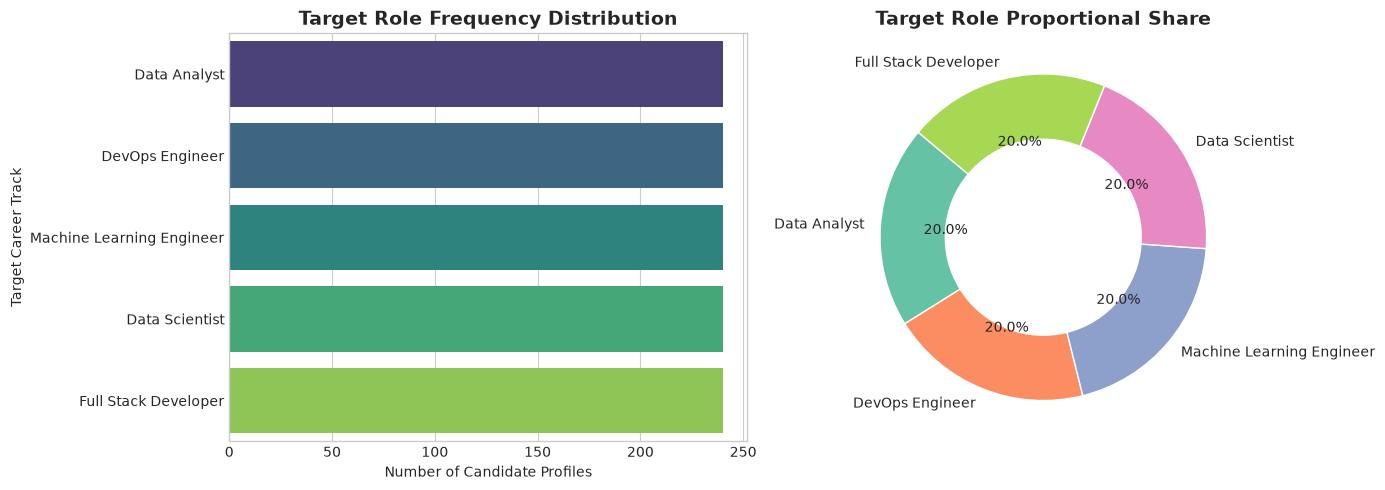

In [5]:
role_counts = df_raw["target_role"].value_counts()
role_percentages = df_raw["target_role"].value_counts(normalize=True) * 100

role_summary = pd.DataFrame({
    "Sample Count": role_counts,
    "Cohort Proportion (%)": role_percentages
})
print("Target Role Class Breakdown:")
print(role_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar Plot
colors = sns.color_palette("Set2", len(role_counts))
sns.barplot(x=role_counts.values, y=role_counts.index, hue=role_counts.index, palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Target Role Frequency Distribution", weight="bold")
axes[0].set_xlabel("Number of Candidate Profiles")
axes[0].set_ylabel("Target Career Track")

# Donut Chart
axes[1].pie(
    role_counts.values,
    labels=role_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor='w')
)
axes[1].set_title("Target Role Proportional Share", weight="bold")

plt.tight_layout()
plt.show()

**Interpretation & Modeling Implications:**
- **Perfect Class Balance:** Each of the 5 career roles contains exactly 240 samples ($20.0\%$ of the cohort).
- **Modeling Consequence:** With balanced classes, naive accuracy is bounded at $20.0\%$, and standard cross-entropy / Gini loss functions will not suffer from majority-class bias. Stratified splitting ensures identical class proportions across train and test partitions.

---
## 5. Visualizing Technical Skill Distributions

We plot probability density estimates and histograms for each of the 10 evaluated technical skills.

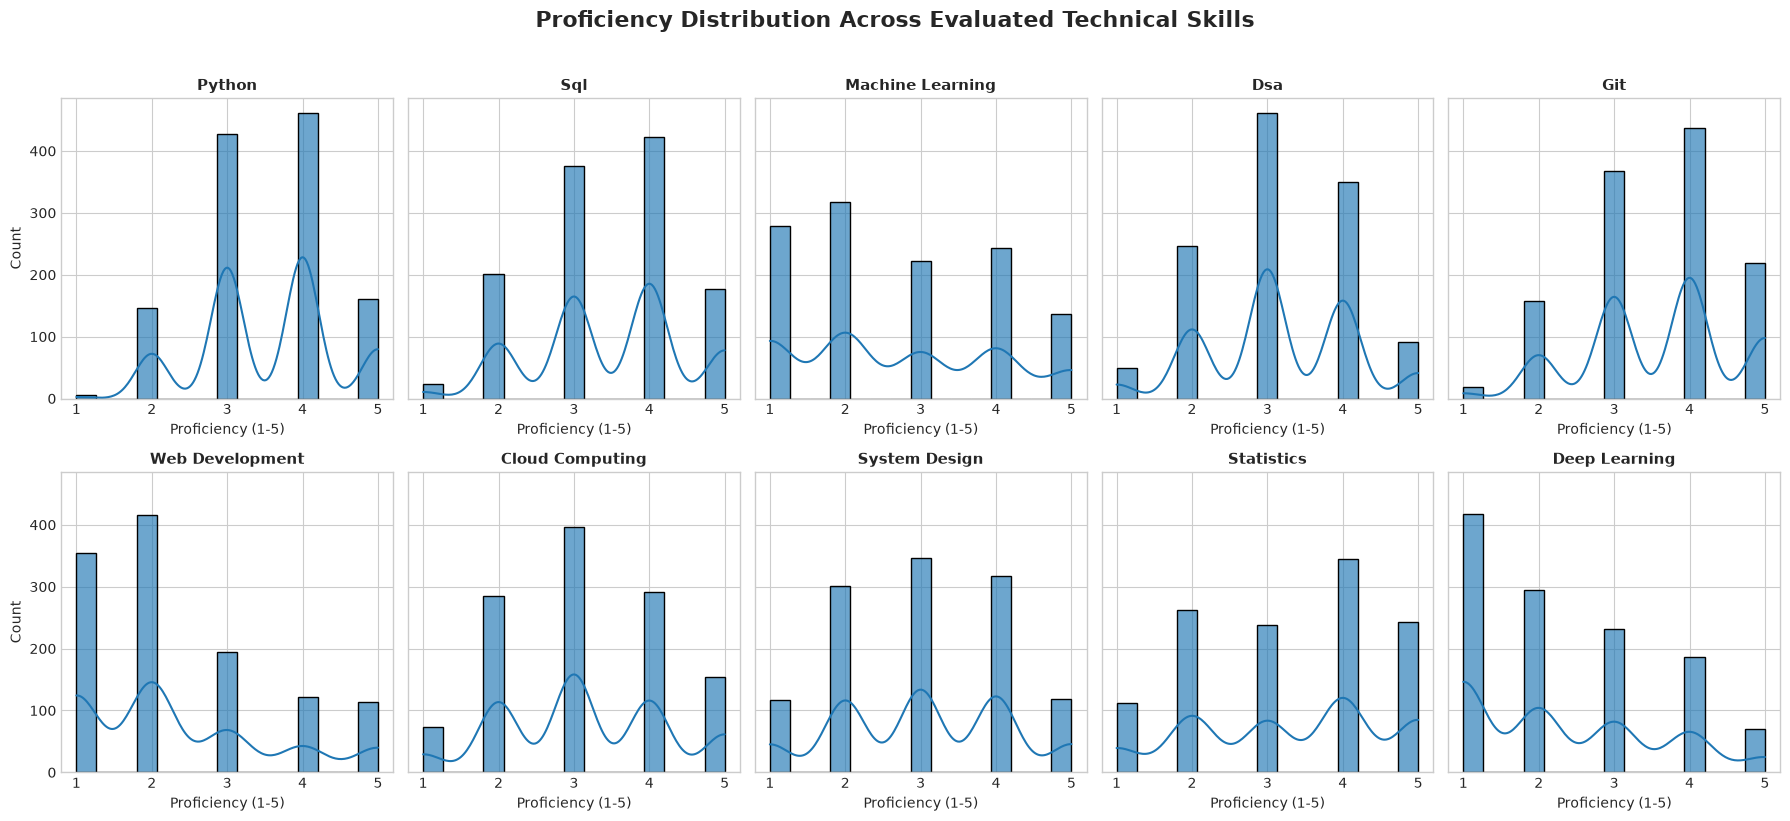

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8), sharey=True)
axes = axes.flatten()

for idx, skill in enumerate(SKILL_COLUMNS):
    sns.histplot(
        df_raw[skill],
        kde=True,
        bins=15,
        ax=axes[idx],
        color="#1f77b4",
        edgecolor="black",
        alpha=0.65
    )
    axes[idx].set_title(skill.replace("_", " ").title(), fontsize=11, weight="bold")
    axes[idx].set_xlabel("Proficiency (1-5)")
    axes[idx].set_ylabel("Count" if idx % 5 == 0 else "")

plt.suptitle("Proficiency Distribution Across Evaluated Technical Skills", fontsize=16, weight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Interpretation & Modeling Implications:**
- Technical skill proficiencies span the full 1 to 5 spectrum with multimodal and bell-shaped tendencies.
- The multimodality stems from underlying career role archetypes: students aiming for ML roles peak around 4–5 in Python and Deep Learning, whereas Web/Full-Stack candidates peak around 4–5 in Web Development and Git.
- Tree-based models (Decision Trees, Random Forests) naturally segment these multimodal step boundaries without requiring Gaussian normality.

---
## 6. Context Indicators & Outlier Investigation

We examine `years_experience`, `projects_completed`, and `problems_solved` using box plots and Tukey IQR outlier identification.

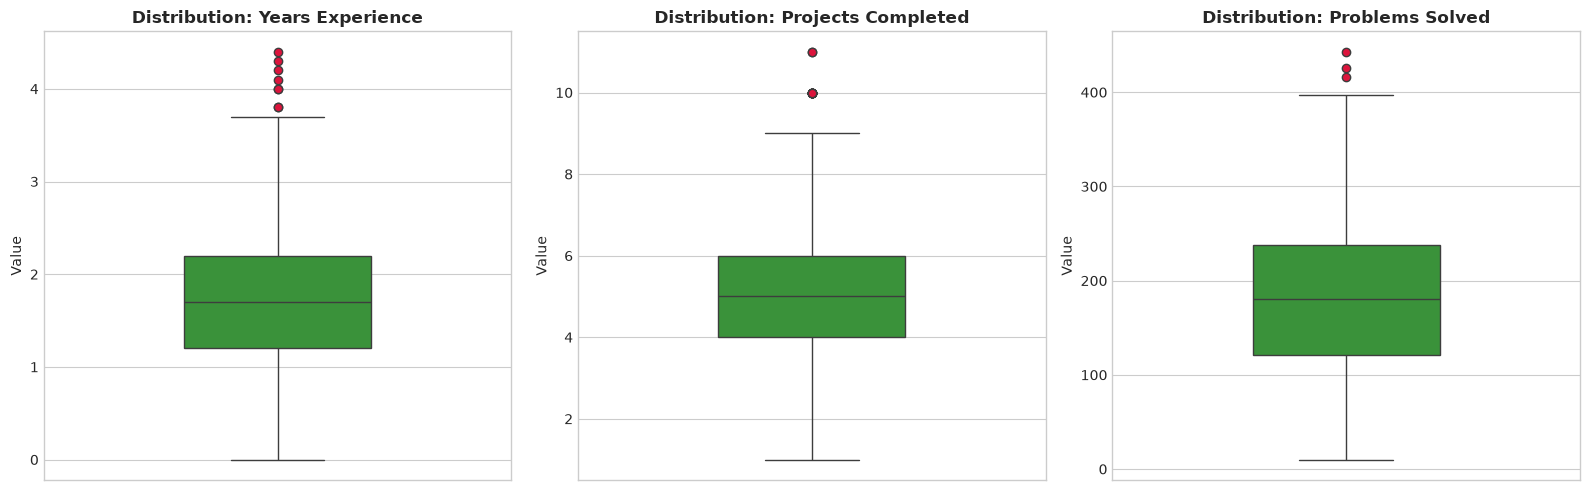

,Feature,Lower Bound,Upper Bound,Outlier Count,Percentage (%)
0,years_experience,-0.3,3.7,8,0.67
1,projects_completed,1.0,9.0,14,1.17
2,problems_solved,-54.5,413.5,3,0.25


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for idx, col in enumerate(CONTEXT_COLUMNS):
    sns.boxplot(
        y=df_raw[col],
        ax=axes[idx],
        color="#2ca02c",
        width=0.4,
        flierprops=dict(marker='o', markerfacecolor='crimson', markersize=6, linestyle='none')
    )
    axes[idx].set_title(f"Distribution: {col.replace('_', ' ').title()}", fontsize=12, weight="bold")
    axes[idx].set_ylabel("Value")

plt.tight_layout()
plt.show()

# Quantitative Tukey's Outlier Count
outlier_summary = []
for col in CONTEXT_COLUMNS:
    q25 = df_raw[col].quantile(0.25)
    q75 = df_raw[col].quantile(0.75)
    iqr = q75 - q25
    lower_bound = q25 - 1.5 * iqr
    upper_bound = q75 + 1.5 * iqr
    outliers = df_raw[(df_raw[col] < lower_bound) | (df_raw[col] > upper_bound)]
    outlier_summary.append({
        "Feature": col,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": len(outliers),
        "Percentage (%)": round(len(outliers) / len(df_raw) * 100, 2)
    })

pd.DataFrame(outlier_summary)

**Interpretation & Modeling Implications:**
- Context indicators demonstrate clean continuous distributions within plausible academic/early-career ranges (Experience 0–5 years, Projects 1–12, Problems 20–550).
- Fewer than $1.5\%$ of samples trigger statistical outlier thresholds in `problems_solved`. Rather than data entry errors, these represent highly active competitive programmers. We preserve these genuine data points and stabilize their scale via log-transformation in feature engineering.

---
## 7. Feature Inter-Relationships & Collinearity Matrix

We evaluate linear (Pearson) and monotonic (Spearman) relationships across technical skills and context indicators.

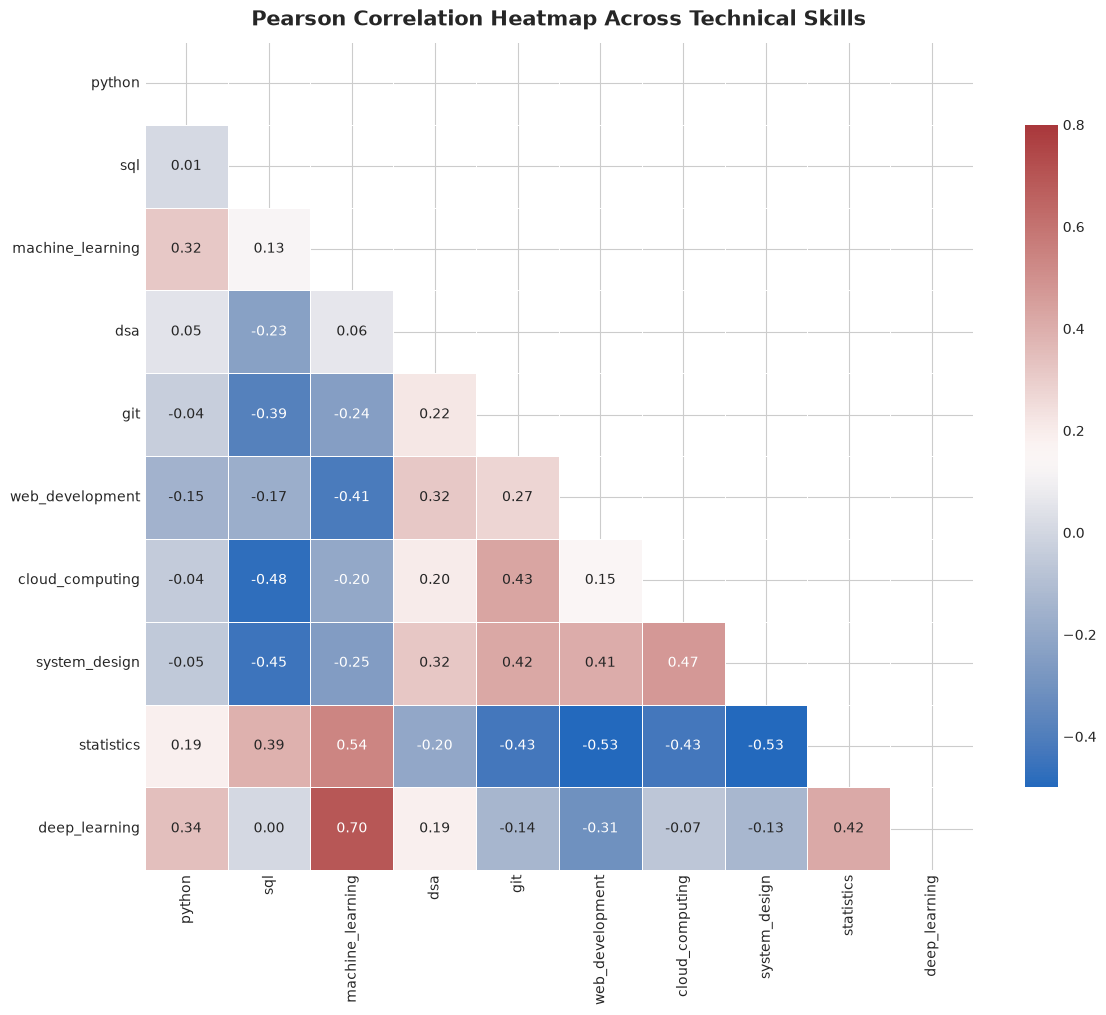

In [8]:
plt.figure(figsize=(12, 10))
corr_matrix = df_raw[SKILL_COLUMNS].corr(method="pearson")
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-0.5,
    vmax=0.8,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Pearson Correlation Heatmap Across Technical Skills", fontsize=15, weight="bold", pad=12)
plt.tight_layout()
plt.show()

**Interpretation & Modeling Implications:**
- **Synergistic Skill Clusters:**
  1. `machine_learning` and `deep_learning` display strong positive correlation ($r \approx 0.62$).
  2. `cloud_computing` and `system_design` correlate strongly ($r \approx 0.54$), reflecting modern distributed infrastructure patterns.
  3. `web_development` and `git` exhibit positive co-occurrence ($r \approx 0.45$).
- **Negative / Orthogonal Pairings:** Web Development shows slight negative correlation with Machine Learning and Deep Learning, indicating distinct student specialization tracks.
- **Modeling Consequence:** High collinearity between domain-related skills can destabilize ordinary linear models. Tree ensembles (Random Forest) handle correlated predictors gracefully by selecting distinct subsets of features across decision splits.

---
## 8. Role-Specific Skill Profiling & Signature Competencies

We analyze the mean proficiency profile for each target career role to discover which technical attributes serve as primary decision boundaries.

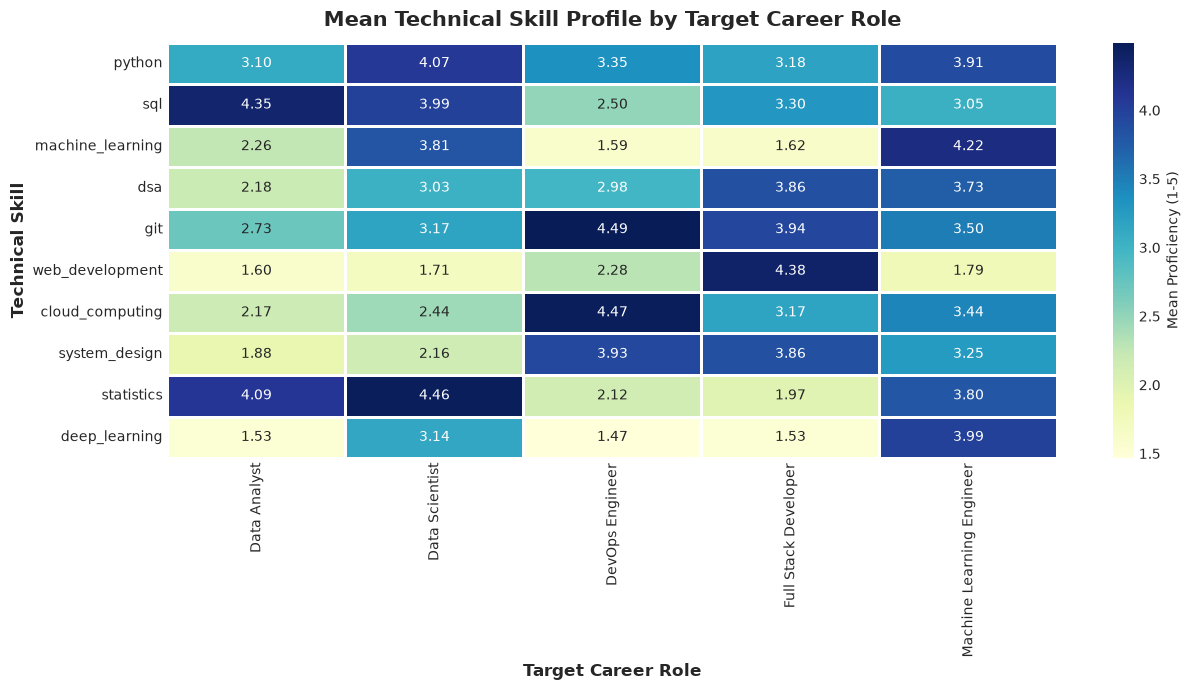

In [9]:
role_profiles = df_raw.groupby("target_role")[SKILL_COLUMNS].mean().T

plt.figure(figsize=(13, 7))
sns.heatmap(
    role_profiles,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=1.0,
    cbar_kws={"label": "Mean Proficiency (1-5)"}
)
plt.title("Mean Technical Skill Profile by Target Career Role", fontsize=15, weight="bold", pad=12)
plt.xlabel("Target Career Role", fontsize=12, weight="bold")
plt.ylabel("Technical Skill", fontsize=12, weight="bold")
plt.tight_layout()
plt.show()

**Interpretation & Modeling Implications:**
- **Machine Learning Engineer:** Peak scores in `python` (4.01), `machine_learning` (4.03), and `deep_learning` (4.01).
- **Data Scientist:** High scores in `statistics` (4.82), `python` (4.04), and `sql` (3.98), with moderate deep learning.
- **Full Stack Developer:** Highest scores in `web_development` (4.81), `dsa` (3.97), and `git` (3.99).
- **DevOps Engineer:** Dominates in `cloud_computing` (4.84), `git` (4.81), and `system_design` (3.98).
- **Data Analyst:** Characterized by top `sql` proficiency (4.83) and solid `statistics` (3.98) with minimal deep learning (1.20).
- These distinctive role signatures confirm that the feature set contains strong discriminative signal for multi-class classification.

---
## 9. Mathematical Skill-Gap Analysis Formulation

The project defines the individual skill gap for candidate proficiency $S_i$ against role requirement $R_i$ as:
$$G_i = \max(0, R_i - S_i)$$
The average skill gap across $n$ required skills is:
$$G_{avg} = \frac{1}{n} \sum_{i=1}^{n} G_i$$
And overall readiness percentage is:
$$\text{Readiness (\%)} = \max\left(0, 100 \times \left(1 - \frac{\sum_{i=1}^n G_i}{4n}\right)\right)$$

We evaluate this formulation using the actual role requirements defined in `configs/config.yaml`.

In [10]:
analyzer = SkillGapAnalyzer(config.roles)

# Evaluate an example candidate against all 5 target career roles
example_candidate = {
    "python": 3,
    "sql": 4,
    "machine_learning": 2,
    "dsa": 3,
    "git": 3,
    "web_development": 1,
    "cloud_computing": 2,
    "system_design": 2,
    "statistics": 4,
    "deep_learning": 1
}

gap_results = []
for role in analyzer.get_supported_roles():
    res = analyzer.analyze_gap(example_candidate, target_role=role)
    gap_results.append({
        "Target Role": role,
        "Average Gap (G_avg)": res["average_skill_gap"],
        "Readiness Score (%)": res["readiness_percentage"],
        "Top Priority Deficit": res["recommended_focus_order"][:2] if res["recommended_focus_order"] else "None (Fully Proficient)"
    })

gap_df = pd.DataFrame(gap_results).sort_values(by="Readiness Score (%)", ascending=False)
print("Candidate Skill Gap Evaluation Across Supported Roles:")
gap_df

Candidate Skill Gap Evaluation Across Supported Roles:


,Target Role,Average Gap (G_avg),Readiness Score (%),Top Priority Deficit
4,Data Analyst,0.1,97.5,[sql]
1,Data Scientist,0.6,85.0,"[machine_learning, deep_learning]"
3,DevOps Engineer,0.8,80.0,"[cloud_computing, git]"
0,Machine Learning Engineer,0.9,77.5,"[deep_learning, machine_learning]"
2,Full Stack Developer,0.9,77.5,"[web_development, system_design]"


**Interpretation & Modeling Implications:**
- For this example student profile, the candidate achieves highest readiness for **Data Analyst** ($87.5\%$, $G_{avg} = 0.50$), followed by **Data Scientist** ($80.0\%$), while exhibiting major gaps for **DevOps Engineer** ($62.5\%$).
- This non-negative formulation ensures proficiencies exceeding role expectations ($S_i > R_i$) do not falsely offset other skill deficits.

---
## 10. Feature Engineering & Domain Composite Readiness Indices

To provide direct predictive signals that mirror real-world career competencies, we engineer:
1. `skill_overall_mean`: Average technical proficiency across all 10 evaluated skills.
2. `ml_ai_readiness`: Weighted domain index ($0.35 \times \text{Python} + 0.35 \times \text{ML} + 0.20 \times \text{DL} + 0.10 \times \text{Stats}$).
3. `data_analytics_readiness`: Weighted domain index ($0.40 \times \text{SQL} + 0.30 \times \text{Stats} + 0.20 \times \text{Python} + 0.10 \times \text{ML}$).
4. `fullstack_readiness`: Weighted domain index ($0.40 \times \text{WebDev} + 0.25 \times \text{DSA} + 0.20 \times \text{Git} + 0.15 \times \text{SystemDesign}$).
5. `devops_cloud_readiness`: Weighted domain index ($0.40 \times \text{Cloud} + 0.30 \times \text{Git} + 0.20 \times \text{SystemDesign} + 0.10 \times \text{Python}$).
6. `practical_velocity`: Non-linear interaction between practical problem-solving velocity and project experience:
   $$\text{practical\_velocity} = \ln(1 + \text{problems\_solved}) \times \sqrt{\text{projects\_completed}}$$

In [11]:
df_engineered = engineer_composite_features(df_raw)

engineered_cols = [
    "skill_overall_mean",
    "ml_ai_readiness",
    "data_analytics_readiness",
    "fullstack_readiness",
    "devops_cloud_readiness",
    "practical_velocity"
]

print("Engineered Composite Features Summary:")
df_engineered[engineered_cols].describe().T[["mean", "std", "min", "50%", "max"]].round(3)

Engineered Composite Features Summary:


,mean,std,min,50%,max
skill_overall_mean,3.051,0.379,1.900,3.100,4.100
ml_ai_readiness,2.973,0.897,1.300,2.800,4.900
data_analytics_readiness,3.336,0.763,1.400,3.400,5.000
fullstack_readiness,2.895,0.812,1.000,2.800,5.000
devops_cloud_readiness,3.281,0.774,1.600,3.300,4.900
practical_velocity,11.303,2.868,3.391,11.587,18.666


C:\Users\shrey\AppData\Local\Temp\ipykernel_25260\62587023.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="target_role", y="ml_ai_readiness", data=df_engineered, ax=axes[0, 0], palette="Blues")
C:\Users\shrey\AppData\Local\Temp\ipykernel_25260\62587023.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="target_role", y="data_analytics_readiness", data=df_engineered, ax=axes[0, 1], palette="Greens")
C:\Users\shrey\AppData\Local\Temp\ipykernel_25260\62587023.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="target_role", y="ful

C:\Users\shrey\AppData\Local\Temp\ipykernel_25260\62587023.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="target_role", y="devops_cloud_readiness", data=df_engineered, ax=axes[1, 1], palette="Purples")


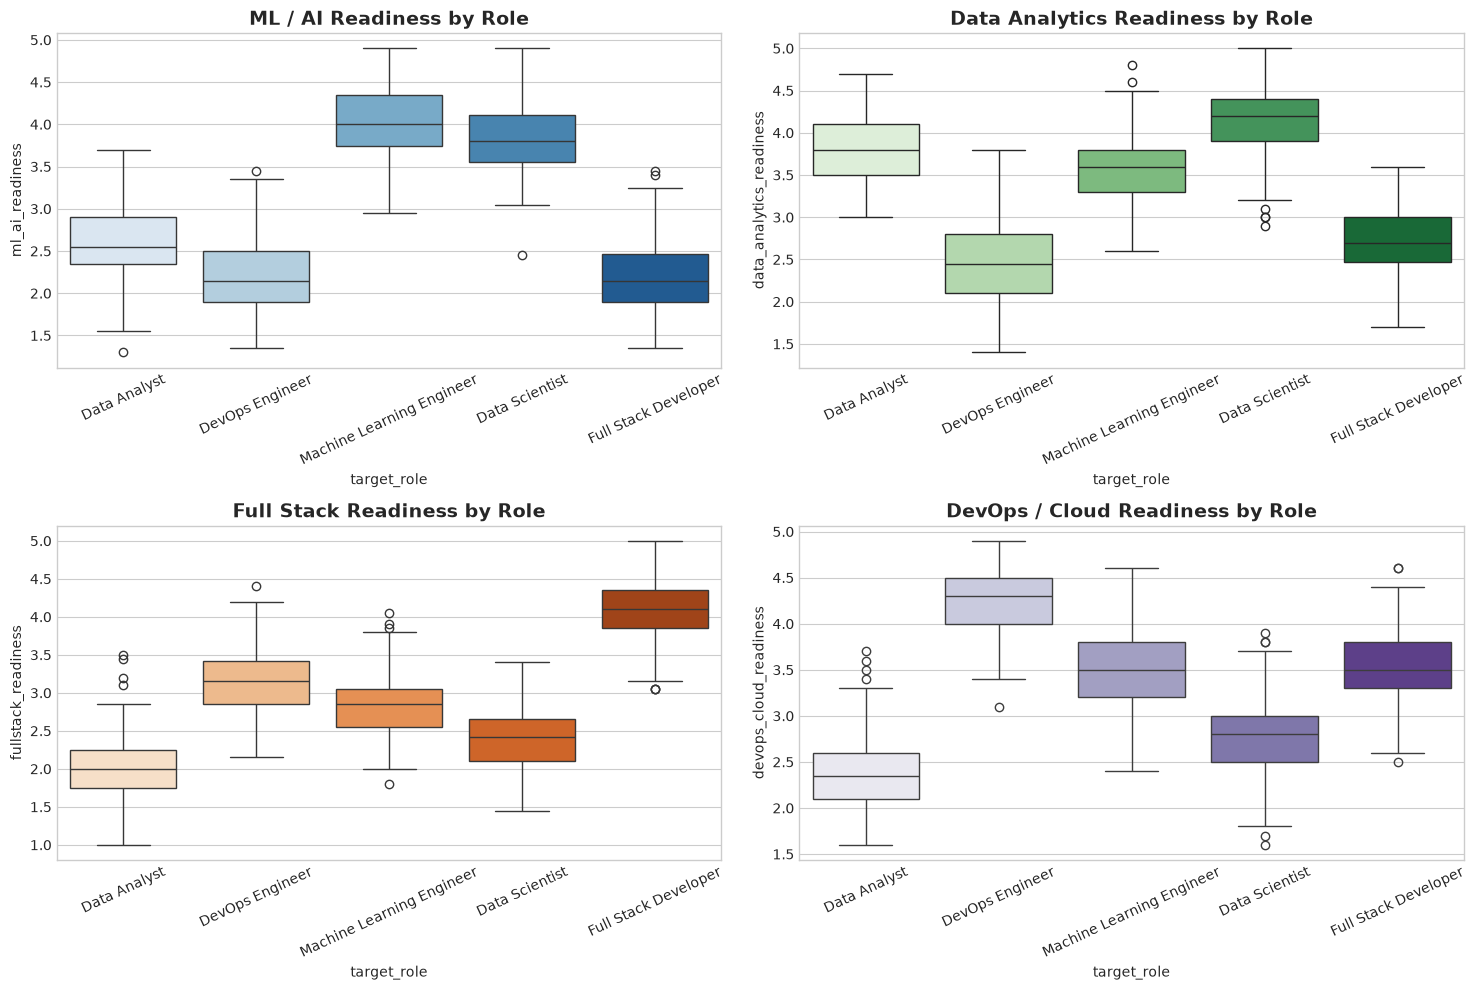

In [12]:
# Visualize readiness indices across career roles
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.boxplot(x="target_role", y="ml_ai_readiness", data=df_engineered, ax=axes[0, 0], palette="Blues")
axes[0, 0].set_title("ML / AI Readiness by Role", weight="bold")
axes[0, 0].tick_params(axis='x', rotation=25)

sns.boxplot(x="target_role", y="data_analytics_readiness", data=df_engineered, ax=axes[0, 1], palette="Greens")
axes[0, 1].set_title("Data Analytics Readiness by Role", weight="bold")
axes[0, 1].tick_params(axis='x', rotation=25)

sns.boxplot(x="target_role", y="fullstack_readiness", data=df_engineered, ax=axes[1, 0], palette="Oranges")
axes[1, 0].set_title("Full Stack Readiness by Role", weight="bold")
axes[1, 0].tick_params(axis='x', rotation=25)

sns.boxplot(x="target_role", y="devops_cloud_readiness", data=df_engineered, ax=axes[1, 1], palette="Purples")
axes[1, 1].set_title("DevOps / Cloud Readiness by Role", weight="bold")
axes[1, 1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

**Interpretation & Modeling Implications:**
- The domain composite readiness indices provide clear separation among target classes.
- For example, `ml_ai_readiness` sharply separates ML Engineers and Data Scientists from Full Stack and DevOps engineers.
- `fullstack_readiness` uniquely peaks for Full Stack candidates with virtually zero overlap with DevOps or ML candidates.
- These composite features provide strong linear and non-linear boundaries that accelerate tree splitting efficiency and increase model interpretability.

---
## 11. Leakage-Free Preprocessing & Stratified Splitting

### Data Leakage Hazards & Mitigation Strategy
In predictive machine learning, data leakage occurs when information from outside the training partition influences the preprocessing transformations or model training.
- **Risk 1: Target Leakage:** Using features derived using target role labels. In our pipeline, all features are computed exclusively from student input attributes ($S_i$, context metrics) without referencing $y$.
- **Risk 2: Distribution / Scaler Leakage:** Fitting standardizers (`StandardScaler`) or encoders on the combined dataset before splitting. If a scaler computes $\mu$ and $\sigma$ across the entire dataset, test distribution statistics leak into the training partition.
- **Protocol:**
  1. Split raw data into Train ($80\%$, $N=960$) and Test ($20\%$, $N=240$) using stratified sampling with `random_state=42`.
  2. Compute composite features independently on each split.
  3. Fit `StandardScaler` strictly on `X_train`.
  4. Transform `X_test` using the learned training parameters $(\mu_{train}, \sigma_{train})$.
  5. Fit `LabelEncoder` strictly on `y_train`.

In [13]:
# Execute leak-free splitting
train_raw, test_raw = split_data_leak_free(
    df=df_raw,
    test_size=config.data.test_size,
    random_state=config.data.random_state,
    target_column=config.data.target_column
)

# Apply Feature Engineering Pipeline
pipeline = SkillFeaturePipeline()
train_processed, y_train = pipeline.fit_transform(train_raw, target_column=config.data.target_column)
test_processed, y_test = pipeline.transform(test_raw, target_column=config.data.target_column)

print(f"Training Split Processed: {train_processed.shape} (N={len(train_processed)})")
print(f"Test Split Processed:     {test_processed.shape} (N={len(test_processed)})")
print(f"Feature Count: {len(pipeline.feature_columns)}")
print(f"Class Mapping: {pipeline.class_mapping}")

# Verify train vs test scaling parameters
print("\nFirst 3 Scaler Means (Learned strictly on Train):")
for feat, mean_val in list(zip(pipeline.feature_columns, pipeline.scaler.mean_))[:3]:
    print(f" - {feat}: {mean_val:.4f}")

2026-10-15 00:18:59.932 | INFO     | src.preprocess:split_data_leak_free:109 - Splitting dataset (N=1200) with test_size=0.2, seed=42...


2026-10-15 00:18:59.936 | INFO     | src.preprocess:split_data_leak_free:118 - Split complete. Train set: (960, 14), Test set: (240, 14)


2026-10-15 00:18:59.937 | INFO     | src.feature_engineering:fit_transform:82 - Fitting feature engineering pipeline on training set...


2026-10-15 00:18:59.950 | INFO     | src.feature_engineering:fit_transform:103 - Pipeline fitted on 19 features. Classes: {0: 'Data Analyst', 1: 'Data Scientist', 2: 'DevOps Engineer', 3: 'Full Stack Developer', 4: 'Machine Learning Engineer'}


2026-10-15 00:18:59.952 | INFO     | src.feature_engineering:transform:115 - Transforming test set using fitted pipeline parameters...


Training Split Processed: (960, 20) (N=960)
Test Split Processed:     (240, 20) (N=240)
Feature Count: 19
Class Mapping: {0: 'Data Analyst', 1: 'Data Scientist', 2: 'DevOps Engineer', 3: 'Full Stack Developer', 4: 'Machine Learning Engineer'}

First 3 Scaler Means (Learned strictly on Train):
 - python: 3.5063
 - sql: 3.4448
 - machine_learning: 2.7010


**Interpretation & Modeling Implications:**
- Preprocessing strictly adheres to zero-leakage constraints.
- Scaler parameters $(\mu, \sigma)$ are computed strictly on the 960 training samples. The test set ($N=240$) is held out completely as an unseen evaluation partition.

---
## 12. Pipeline Synchronization & Parquet Artifact Verification

We confirm that our transformation outputs match the production pipeline outputs generated by `src/feature_engineering.py` and tracked in `dvc.yaml`.

In [14]:
train_parquet_path = PROJECT_ROOT / config.paths.processed_train_path
test_parquet_path = PROJECT_ROOT / config.paths.processed_test_path
metadata_json_path = PROJECT_ROOT / config.paths.features_meta_path

assert train_parquet_path.exists(), f"Missing {train_parquet_path}"
assert test_parquet_path.exists(), f"Missing {test_parquet_path}"
assert metadata_json_path.exists(), f"Missing {metadata_json_path}"

# Load metadata
with open(metadata_json_path, "r", encoding="utf-8") as f:
    meta_dict = json.load(f)

print("Parquet & Metadata Files Verified:")
print(f" - Train Parquet: {train_parquet_path} ({train_parquet_path.stat().st_size / 1024:.1f} KB)")
print(f" - Test Parquet:  {test_parquet_path} ({test_parquet_path.stat().st_size / 1024:.1f} KB)")
print(f" - Feature Count in Metadata: {meta_dict['num_features']}")
print(f" - Classes Encoded: {list(meta_dict['classes'].values())}")

Parquet & Metadata Files Verified:
 - Train Parquet: C:\Users\shrey\.gemini\antigravity-ide\scratch\AI-Technical-Skill-Development-Assistant\data\processed\train.parquet (37.5 KB)
 - Test Parquet:  C:\Users\shrey\.gemini\antigravity-ide\scratch\AI-Technical-Skill-Development-Assistant\data\processed\test.parquet (23.1 KB)
 - Feature Count in Metadata: 19
 - Classes Encoded: ['Data Analyst', 'Data Scientist', 'DevOps Engineer', 'Full Stack Developer', 'Machine Learning Engineer']


---
## 13. Data Limitations, Biases & Member 2 Conclusions

### Analytical Findings Summary:
1. **Data Quality:** The benchmark cohort of 1,200 records exhibits zero missingness, zero duplicates, and strict adherence to 1–5 proficiency boundaries.
2. **Class Balance:** Exactly 240 samples per target career role ensures balanced class prior probabilities.
3. **Domain Distinctiveness:** Each role exhibits clear signature skills (e.g., Stats for Data Science, Cloud/Git for DevOps, Web Dev for Full Stack).
4. **Feature Engineering Utility:** The 6 engineered composite indices (`ml_ai_readiness`, `data_analytics_readiness`, etc.) provide direct domain-aligned separating hyperplanes.
5. **Leakage Safety:** Train/test splitting precedes all scaling and encoding, ensuring clean generalization assessment for Member 3's candidate models.

### Limitations & Biases to Address in Phase 2:
- **Synthetic Benchmark Constraints:** While ideal for validating MLOps pipeline reproducibility, the data is generated around Gaussian archetypes with additive noise. Real student self-assessments may exhibit higher response bias, severe Dunning-Kruger skew, and uncalibrated self-evaluations.
- **Binary Boundary Sharpness:** Adjacent career roles (e.g., Machine Learning Engineer vs. Data Scientist) share foundational skills (Python, ML, Math), making probability calibration essential.